# Heatline — from a neuron to a May heatwave ANN

Assessed scope: **Nagpur, May, NumPy backpropagation**. The seven supporting experiments use the supplied lab-printed COs. Weather dashboard integration is a product extension; fuzzy/GA/deeper ensemble are optional. Run from this notebook folder or the repository root. This notebook reads measured artifacts rather than silently retraining models.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd() if (Path.cwd()/'src').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
from src.lab_examples import *
from src.ann_numpy import EBPANetwork
from src.sc_baselines import PerceptronRuleClassifier
ARTIFACTS=ROOT/'artifacts/heatline'
pd.DataFrame(LAB_MAPPING)

,experiment,title,co,connection
0,1,Activation functions,CO1,"Identity, binary/bipolar step and sigmoid, ram..."
1,2,McCulloch–Pitts neuron,CO1,"Fixed-threshold NAND, NOR and recurrent memory..."
2,3,Hebbian learning,CO3,Binary/bipolar association through weight upda...
3,4,Perceptron learning,CO2,AND is separable; XOR is not. A single-layer w...
4,5,Delta learning,CO2,Error-driven sigmoid updates; distinguish from...
5,6,Multilayer perceptron,CO2,A hidden layer learns XOR; the heatwave model ...
6,7,Error backpropagation,CO2,Numerical 2–2–1 trace; α=0.25 denotes η; μ=0.


## 1 · Activation functions · CO1
An artificial neuron computes a weighted sum plus bias. Identity and ramp define continuous mappings; binary and bipolar steps are threshold decisions. Binary sigmoid is σ(a); bipolar sigmoid is 2σ(a)−1=tanh(a/2), with derivative (1−f(a)²)/2. Step at zero belongs to the positive class here; ramp is clipped to [0,1].

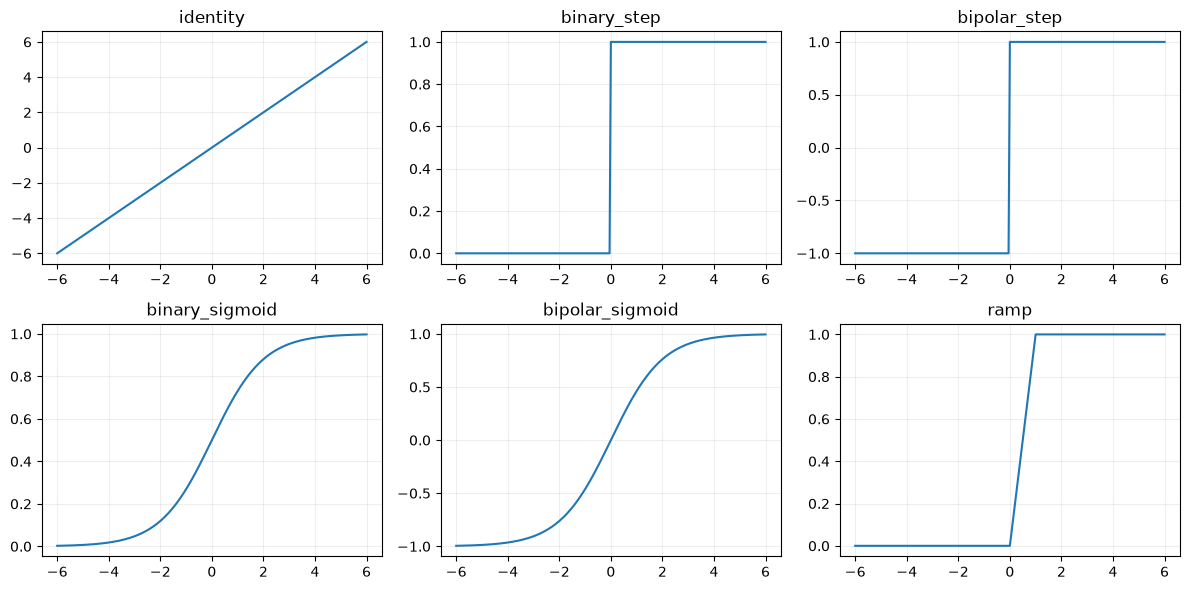

In [2]:
x=np.linspace(-6,6,241)
fig,axes=plt.subplots(2,3,figsize=(12,6))
for ax,(name,values) in zip(axes.flat,activation_values(x).items()):
    ax.plot(x,values); ax.set_title(name); ax.grid(alpha=.2)
fig.tight_layout(); plt.show()

## 2 · McCulloch–Pitts · CO1
Fixed weights implement NAND and NOR. The memory example feeds the previous output back into the threshold neuron. It is a reset-dominant memory convention, displayed explicitly; it does not learn weights.

In [3]:
examples=mcp_examples()
display(pd.DataFrame(examples['logic']))
print(examples['memory_rule'])
display(pd.DataFrame(examples['memory']))

,inputs,nand,nor
0,"[0, 0]",1,1
1,"[0, 1]",1,0
2,"[1, 0]",1,0
3,"[1, 1]",0,0


q_next = step(set + q_previous - 2*reset - 0.5)


,set,reset,previous,next
0,0,0,0,0
1,1,0,0,1
2,0,0,1,1
3,0,0,1,1
4,0,1,1,0
5,0,0,0,0


## 3 · Hebbian association · CO3
For the supervised association example Δw=ηxt, Δb=ηt. Binary zeros do not contribute; bipolar negatives can create signed associations. Hebbian learning does not minimize the classification error used by backpropagation.

In [4]:
for bipolar in [False,True]:
    result=hebbian_example(bipolar)
    print(result['encoding']); display(pd.DataFrame(result['steps']))

binary


,x,target,delta_w,delta_b,weights,bias
0,"[0.0, 0.0]",0.0,"[0.0, 0.0]",0.0,"[0.0, 0.0]",0.0
1,"[0.0, 1.0]",0.0,"[0.0, 0.0]",0.0,"[0.0, 0.0]",0.0
2,"[1.0, 0.0]",0.0,"[0.0, 0.0]",0.0,"[0.0, 0.0]",0.0
3,"[1.0, 1.0]",1.0,"[1.0, 1.0]",1.0,"[1.0, 1.0]",1.0


bipolar


,x,target,delta_w,delta_b,weights,bias
0,"[-1.0, -1.0]",-1.0,"[1.0, 1.0]",-1.0,"[1.0, 1.0]",-1.0
1,"[-1.0, 1.0]",-1.0,"[1.0, -1.0]",-1.0,"[2.0, 0.0]",-2.0
2,"[1.0, -1.0]",-1.0,"[-1.0, 1.0]",-1.0,"[1.0, 1.0]",-3.0
3,"[1.0, 1.0]",1.0,"[1.0, 1.0]",1.0,"[2.0, 2.0]",-2.0


## 4 · Perceptron and separability · CO2
A single threshold boundary can represent bipolar AND. XOR requires two disjoint positive regions and cannot be separated by one straight line. This establishes an architecture limitation; it does not prove any particular weather dataset needs a nonlinear model.

In [5]:
binary=np.array([[0,0],[0,1],[1,0],[1,1]],float)
X=2*binary-1
and_target=np.array([0,0,0,1])
xor_target=np.array([0,1,1,0])
for name,target in [('AND',and_target),('XOR',xor_target)]:
    net=PerceptronRuleClassifier(eta=.1,max_epochs=100,random_state=42).fit(X,target)
    print(name,'bipolar inputs:',X.tolist(),'bipolar targets:',(2*target-1).tolist(),'binary predictions:',net.predict(X).tolist())

AND bipolar inputs: [[-1.0, -1.0], [-1.0, 1.0], [1.0, -1.0], [1.0, 1.0]] bipolar targets: [-1, -1, -1, 1] binary predictions: [0, 0, 0, 1]
XOR bipolar inputs: [[-1.0, -1.0], [-1.0, 1.0], [1.0, -1.0], [1.0, 1.0]] bipolar targets: [-1, 1, 1, -1] binary predictions: [1, 1, 1, 1]


## 5 · Delta learning · CO2
For sigmoid output and half-squared-error the update signal is (t−ŷ)f′(a). Binary targets are 0/1; bipolar sigmoid uses −1/+1 targets and its different derivative. True LMS/ADALINE uses a linear output a and derivative 1. Applying sigmoid and its derivative is a nonlinear sigmoid delta neuron, even if an old filename used ADALINE.

In [6]:
for bipolar in [False,True]:
    print(json.dumps(delta_example(bipolar),indent=2))

{
  "experiment": 5,
  "co": "CO2",
  "encoding": "binary",
  "inputs": [
    1.0,
    -1.0
  ],
  "initial_weights": [
    0.2,
    -0.1
  ],
  "initial_bias": 0.1,
  "eta": 0.25,
  "target": 1.0,
  "net": 0.4,
  "output": 0.598687660112452,
  "derivative": 0.24026074574152914,
  "delta": 0.0964196020566603,
  "updated_weights": [
    0.2241049005141651,
    -0.12410490051416508
  ],
  "updated_bias": 0.12410490051416508,
  "linear_lms_distinction": "ADALINE uses output=net and derivative=1. This sigmoid loss is not quadratic in weights."
}
{
  "experiment": 5,
  "co": "CO2",
  "encoding": "bipolar",
  "inputs": [
    1.0,
    -1.0
  ],
  "initial_weights": [
    0.2,
    -0.1
  ],
  "initial_bias": 0.1,
  "eta": 0.25,
  "target": 1.0,
  "net": 0.4,
  "output": 0.197375320224904,
  "derivative": 0.4805214914830583,
  "delta": 0.3856784082266412,
  "updated_weights": [
    0.2964196020566603,
    -0.19641960205666031
  ],
  "updated_bias": 0.19641960205666031,
  "linear_lms_distinction

## 6 · Multilayer XOR · CO2
The hidden layer permits a nonlinear decision boundary. The assessed climate network has 26 lagged inputs, one hidden layer (8,16,32 compared), and one binary sigmoid output. The XOR example below uses the same forward/backward implementation; it is a mathematical demonstration rather than a weather performance claim.

In [7]:
xor=EBPANetwork(2,8,activation='bipolar_sigmoid',learning_rate=.3,momentum=.9,seed=42,loss='binary_cross_entropy')
xor.train(binary,xor_target,max_epochs=2000,batch_size=4)
print('XOR scores:',xor.predict_proba(binary))
assert np.array_equal(xor.predict(binary),xor_target)

XOR scores: [1.14698178e-04 9.99720375e-01 9.99713224e-01 3.81800727e-04]


## 7 · One 2–2–1 backpropagation update · CO2
Inputs [0,1], target 1, binary sigmoid. The supplied α=0.25 means learning rate **η=0.25**; momentum **μ=0**. Initial weights below are an explicitly chosen illustrative fixture because worksheet weights were not supplied. All hidden error signals use the old output weights; all gradients are calculated before applying updates.

δₖ=(t−ŷ)ŷ(1−ŷ), δⱼ=δₖwⱼzⱼ(1−zⱼ). Then Δwⱼ=ηδₖzⱼ, Δvᵢⱼ=ηδⱼxᵢ; bias updates use input 1.

In [8]:
trace=backpropagation_trace()
print(json.dumps(trace,indent=2))
assert abs(trace['forward']['output']-0.5810319481280129)<1e-14
assert trace['loss_after']<trace['loss_before']

{
  "experiment": 7,
  "co": "CO2",
  "fixture": "illustrative-exp7-v1",
  "initial_weights_note": "Explicit illustrative weights; not supplied worksheet weights.",
  "inputs": [
    0.0,
    1.0
  ],
  "target": 1.0,
  "eta": 0.25,
  "worksheet_alpha": 0.25,
  "mu": 0.0,
  "loss": "half_squared_error",
  "activation": "binary_sigmoid",
  "initial": {
    "V": [
      [
        0.1,
        0.2
      ],
      [
        0.3,
        0.4
      ]
    ],
    "v0": [
      0.1,
      -0.1
    ],
    "W": [
      0.5,
      -0.3
    ],
    "w0": 0.2
  },
  "forward": {
    "hidden_net": [
      0.4,
      0.30000000000000004
    ],
    "hidden": [
      0.598687660112452,
      0.574442516811659
    ],
    "output_net": 0.3270110750127283,
    "output": 0.5810319481280128
  },
  "backward": {
    "error": 0.41896805187198716,
    "delta_output": 0.10199099474234853,
    "delta_hidden": [
      0.012252216227858518,
      -0.007479763914712277
    ]
  },
  "updates": {
    "V": [
      [
    

## Consistent objectives and independent derivatives
Textbook L=mean[½(ŷ−t)²] gives output-logit derivative (ŷ−t)ŷ(1−ŷ). BCE gives ŷ−t. Positive weight p multiplies the positive term in both loss and derivative: a(t)=1+(p−1)t, BCE derivative a(t)ŷ−pt. η controls step size; μ carries the previous parameter update. The primary study uses p=1.

Finite differences and an independently written PyTorch float64 graph check every weight and bias for both sigmoid activations and both objectives. Run `python -m pytest tests/test_ann_gradients.py -q` for these checks; PyTorch is an independent reference, not the training implementation.

In [9]:
model=json.loads((ARTIFACTS/'model.json').read_text())
experiments=json.loads((ARTIFACTS/'experiments.json').read_text())
print('Architecture:',model['architecture'])
print('Selection:',model['selection_policy'])
display(pd.DataFrame(model['splits']))
display(pd.DataFrame(model['metrics']))

Architecture: {'inputs': 26, 'hidden': 8, 'activation': 'bipolar_sigmoid', 'loss': 'binary_cross_entropy'}
Selection: Highest mean 2011–2014 average precision across seeds 7,21,42; tie: lower mean Brier, smaller hidden layer. Deploy fixed seed 42. Eta .05, mu .9 fixed.


,name,years,days,positives
0,train,1981–2010,930,55
1,selection,2011–2014,124,15
2,calibration,2015–2018,124,8
3,retrospective,2019–2026,248,8


,model,pr_auc,precision,recall,f1,brier,tn,fp,fn,tp,threshold,raw_brier,calibration
0,NumPy ANN,0.363649,0.500000,0.250,0.333333,0.024578,238,2,6,2,0.498419,0.025086,"Platt scaling, 2015–2018"
1,ANN textbook squared error,0.437451,0.500000,0.500,0.500000,0.025089,236,4,4,4,0.196504,0.024054,"Platt scaling, 2015–2018"
2,ANN cross-entropy,0.363649,0.500000,0.250,0.333333,0.024578,238,2,6,2,0.498419,0.025086,"Platt scaling, 2015–2018"
3,Persistence,0.180876,0.428571,0.375,0.400000,0.036290,236,4,5,3,0.500000,0.036290,None
4,Climatology,0.113591,0.067308,0.875,0.125000,0.030900,143,97,1,7,0.061111,0.030900,None
5,Perceptron,0.444628,0.500000,0.125,0.200000,0.027793,239,1,7,1,0.143505,0.083328,"Platt scaling, 2015–2018"
6,Sigmoid delta rule,0.488601,0.500000,0.250,0.333333,0.022114,238,2,6,2,0.521422,0.021997,"Platt scaling, 2015–2018"
7,Logistic regression,0.499146,0.500000,0.250,0.333333,0.022259,238,2,6,2,0.474919,0.022622,"Platt scaling, 2015–2018"


## Data and experiment interpretation
1981–2010 trains the ANN, scaler and frozen reference normals; 2011–2014 selects the architecture/objective and early-stopping epoch; 2015–2018 fits Platt scaling and selects the F1 decision threshold. 2019–2026 is retrospective evaluation: these years were previously examined in the legacy project. April primes seven-day May lags. Missing dates and duplicate observations fail explicitly.

The target `nagpur-grid-proxy-v1` is Tmax≥45°C OR (Tmax≥40°C and reference departure≥4.5°C). It is an IMD-inspired single-grid daily proxy, not an official station-based spatial/persistence declaration. The old adjusted rule is preserved in the legacy archive, not chosen to force a desired prevalence.

mean       std  count
activation      hidden loss                                           
binary_sigmoid  8      binary_cross_entropy  0.803716  0.037410      3
                       half_squared_error    0.764203  0.024543      3
                16     binary_cross_entropy  0.811426  0.026994      3
                       half_squared_error    0.766818  0.027536      3
                32     binary_cross_entropy  0.858833  0.003128      3
                       half_squared_error    0.791851  0.022040      3
bipolar_sigmoid 8      binary_cross_entropy  0.873739  0.043536     18
                       half_squared_error    0.868320  0.058788      3
                16     binary_cross_entropy  0.864012  0.012674      3
                       half_squared_error    0.852974  0.032262      3
                32     binary_cross_entropy  0.851760  0.046293      3
                       half_squared_error    0.812730  0.041972      3

,date,score,probability,tmax,actual,prediction
0,2019-05-27,0.204338,0.182832,45.4,1,0
1,2019-05-31,0.054716,0.053902,45.1,1,0
2,2020-05-24,0.153854,0.140122,45.2,1,0
3,2026-05-20,0.104169,0.097553,45.4,1,0
4,2026-05-21,0.538251,0.472912,45.2,1,0
5,2026-05-25,0.108685,0.101459,45.1,1,0


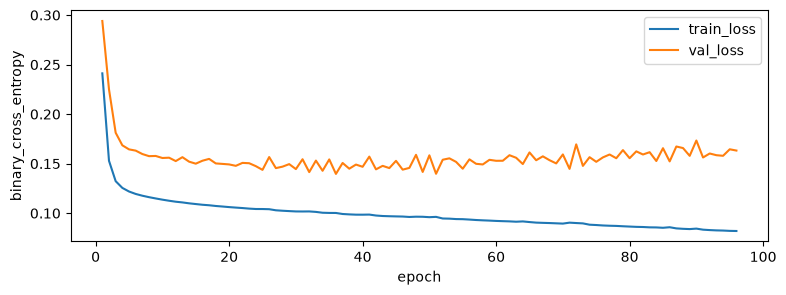

In [10]:
runs=pd.DataFrame(experiments['runs'])
display(runs.groupby(['activation','hidden','loss'])['pr_auc'].agg(['mean','std','count']))
display(pd.DataFrame(experiments['missed_events'])[['date','score','probability','tmax','actual','prediction']])
curve=pd.DataFrame(model['training_history'])
curve.plot(x='epoch',y=['train_loss','val_loss'],figsize=(9,3));plt.ylabel(model['architecture']['loss']);plt.show()

## Results and limitations
Read the measured table above, including cases where a simpler baseline wins. PR-AUC here means average precision. Brier score checks squared probability error; Platt scaling is an estimated transformation, not a guarantee of calibration. Only 8 positives occur in the 248 retrospective days, and neighboring days are correlated. Neither the model nor the provider weather dashboard is an official warning service. ERA5 is delayed; live/regional ANN output is unavailable until compatible timely inputs have separate validation.

Reports: `docs/ACADEMIC_REPORT.md`, `docs/ACADEMIC_APPENDIX.md`. Original source/results: `legacy/original-experiment.zip`.